# 10 — DistilBERT: Final Evaluation and Research Findings

**Research project:** Explainability-Guided Feature Analysis for Reducing False Positives in Phishing Email Detection Without Increasing False Negatives

This notebook presents the final evaluation of the official DistilBERT baseline and the SHAP-guided corrective fine-tuning model. Both sets of results refer to the same **10,716-email test set**. The comparison examines classification errors, overall performance, and whether the final model met the research objective.

## 1. Evaluation objective and class definitions

The objective was to **reduce false positives without increasing false negatives**. Legitimate email is class **0**, and phishing email is class **1**. The study uses the following classification-outcome terminology consistently:

**Table 10.1. Classification outcome definitions**

| Outcome | Meaning |
|:---|:---|
| TP | Legitimate email correctly classified as legitimate |
| FP | Legitimate email incorrectly classified as phishing |
| FN | Phishing email incorrectly classified as legitimate |
| TN | Phishing email correctly classified as phishing |

The confusion matrices below show **actual classes in rows** and **predicted classes in columns**. Performance metrics such as precision and recall are calculated for **phishing (class 1)**, using the class-1 predictions and labels.

## 2. Evaluation data and model comparison

**Table 10.2. Evaluation setting**

| Setting | Recorded value |
|:---|:---|
| Cleaned dataset | 53,577 emails |
| Original training set | 42,861 emails |
| Fixed test set | 10,716 emails |
| Legitimate test emails | 4,748 |
| Phishing test emails | 5,968 |
| Baseline model | Official fine-tuned DistilBERT |
| Final model | SHAP-guided corrective fine-tuned DistilBERT |
| Classification threshold | 0.50 |

The final model was fine-tuned from the saved baseline using the original training records, 21 synthetic legitimate-email examples, and 21 replayed phishing training records. The fine-tuning procedure is documented in Notebook 09.

## 3. Classification results

**Table 10.3. Baseline and final classification outcomes**

| Classification outcome | Official baseline | Final model | Change |
|:---|---:|---:|---:|
| TP — Correct legitimate | 4,717 | 4,722 | +5 |
| **FP — Legitimate classified as phishing** | **31** | **26** | **−5** |
| **FN — Phishing classified as legitimate** | **22** | **17** | **−5** |
| TN — Correct phishing | 5,946 | 5,951 | +5 |
| **Total test emails** | **10,716** | **10,716** | **0** |

**Table 10.4. Confusion matrices (actual class × predicted class)**

| Model | Actual class | Predicted legitimate (0) | Predicted phishing (1) | Row total |
|:---|:---|---:|---:|---:|
| Official baseline | Legitimate (0) | 4,717 | 31 | 4,748 |
| Official baseline | Phishing (1) | 22 | 5,946 | 5,968 |
| **Final model** | Legitimate (0) | **4,722** | **26** | **4,748** |
| **Final model** | Phishing (1) | **17** | **5,951** | **5,968** |

The final model correctly classified five additional legitimate emails and five additional phishing emails. False positives decreased from **31 to 26**, while false negatives decreased from **22 to 17**.

In [1]:
import numpy as np

# Rows: actual legitimate, actual phishing.
# Columns: predicted legitimate, predicted phishing.
baseline_cm = np.array([[4717, 31], [22, 5946]])
final_cm = np.array([[4722, 26], [17, 5951]])

assert baseline_cm.sum() == final_cm.sum() == 10_716
assert np.array_equal(baseline_cm.sum(axis=1), [4748, 5968])
assert np.array_equal(final_cm.sum(axis=1), [4748, 5968])
assert baseline_cm[0, 1] == 31 and final_cm[0, 1] == 26
assert baseline_cm[1, 0] == 22 and final_cm[1, 0] == 17
print('Classification counts and class totals verified.')

Classification counts and class totals verified.


## 4. Final performance metrics

**Table 10.5. Official performance comparison**

| Performance measure | Official baseline | Final model | Direction |
|:---|---:|---:|:---|
| Accuracy | 0.995054 | **0.995987** | Improved |
| Precision (phishing) | 0.994813 | **0.995650** | Improved |
| Recall (phishing) | 0.996314 | **0.997151** | Improved |
| F1-score (phishing) | 0.995563 | **0.996400** | Improved |
| ROC-AUC | 0.999262 | **0.999384** | Improved |
| False positives | 31 | **26** | Reduced |
| False negatives | 22 | **17** | Reduced |

Accuracy, precision, recall, and F1-score can be checked from the confusion matrices. ROC-AUC is reported from the recorded probability-based evaluation and cannot be calculated from a single confusion matrix.

In [2]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def metrics_from_cm(cm):
    # Positive class for these metrics is phishing (label 1).
    actual = np.repeat([0, 1], cm.sum(axis=1))
    predicted = np.concatenate([
        np.repeat([0, 1], cm[0]),
        np.repeat([0, 1], cm[1]),
    ])
    return {
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, pos_label=1),
        'Recall': recall_score(actual, predicted, pos_label=1),
        'F1-score': f1_score(actual, predicted, pos_label=1),
    }

for label, cm in [('Baseline', baseline_cm), ('Final model', final_cm)]:
    values = metrics_from_cm(cm)
    print(label + ': ' + ', '.join(f'{k}={v:.6f}' for k, v in values.items()))

assert round(metrics_from_cm(baseline_cm)['Accuracy'], 6) == 0.995054
assert round(metrics_from_cm(final_cm)['Accuracy'], 6) == 0.995987

Baseline: Accuracy=0.995054, Precision=0.994813, Recall=0.996314, F1-score=0.995563
Final model: Accuracy=0.995987, Precision=0.995650, Recall=0.997151, F1-score=0.996400


## 5. Confusion matrix visualization

**Figure 10.1.** Confusion matrices for the official baseline and final model. The horizontal axis shows predicted classes; the vertical axis shows actual classes.

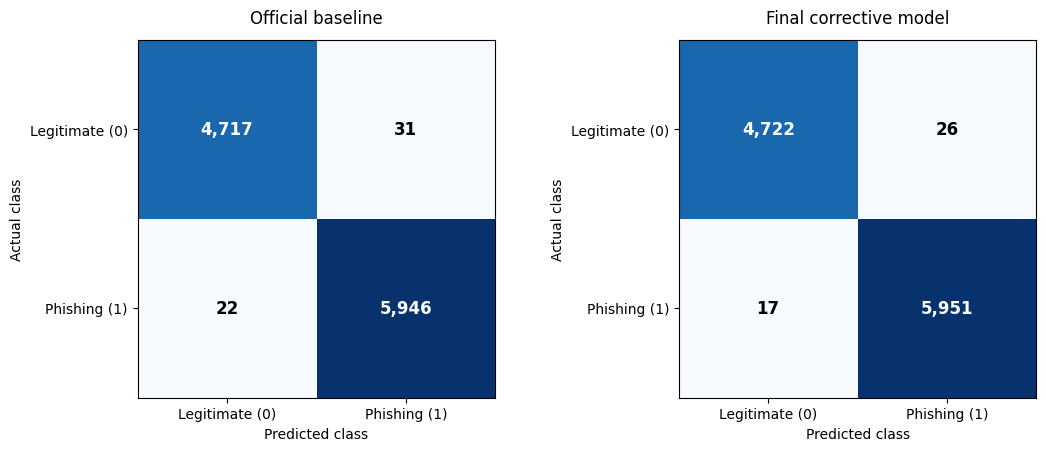

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4), constrained_layout=True)
for ax, cm, title in zip(axes, [baseline_cm, final_cm],
                          ['Official baseline', 'Final corrective model']):
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=6000)
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xticks([0, 1], labels=['Legitimate (0)', 'Phishing (1)'])
    ax.set_yticks([0, 1], labels=['Legitimate (0)', 'Phishing (1)'])
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, f'{value:,}', ha='center', va='center',
                color='white' if value > 3000 else 'black', fontsize=12, fontweight='bold')
plt.show()

## 6. False-positive and false-negative comparison

**Table 10.6. Error reduction**

| Error measure | Official baseline | Final model | Reduction | Relative reduction |
|:---|---:|---:|---:|---:|
| False positives | 31 | **26** | 5 | **16.13%** |
| False negatives | 22 | **17** | 5 | **22.73%** |
| **Total errors** | **53** | **43** | **10** | **18.87%** |

**Figure 10.2.** Comparison of false-positive and false-negative counts.

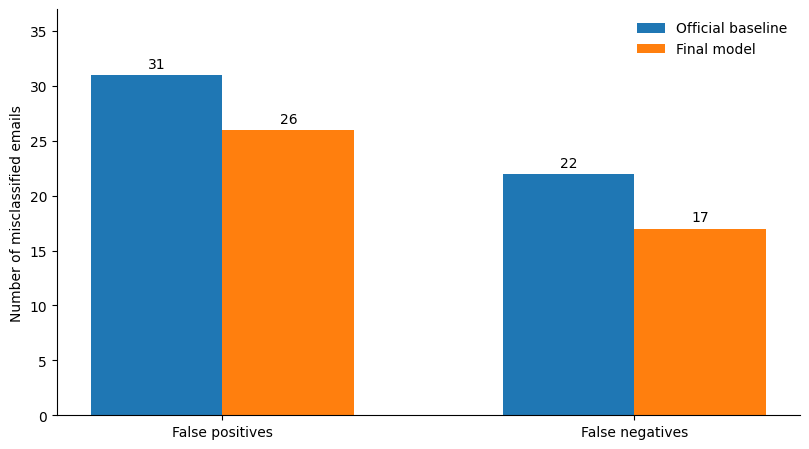

In [4]:
categories = ['False positives', 'False negatives']
baseline_errors = [31, 22]
final_errors = [26, 17]
x = np.arange(len(categories))
width = 0.32
fig, ax = plt.subplots(figsize=(8.2, 4.6))
a = ax.bar(x - width/2, baseline_errors, width, label='Official baseline')
b = ax.bar(x + width/2, final_errors, width, label='Final model')
ax.set_xticks(x, categories)
ax.set_ylabel('Number of misclassified emails')
ax.set_ylim(0, 37)
ax.legend(frameon=False)
ax.bar_label(a, padding=3)
ax.bar_label(b, padding=3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

assert round((31 - 26) / 31 * 100, 2) == 16.13
assert round((22 - 17) / 22 * 100, 2) == 22.73
assert round((53 - 43) / 53 * 100, 2) == 18.87

## 7. ROC-AUC and ROC curve

ROC-AUC evaluates how well the model ranks phishing emails above legitimate emails across classification thresholds. The recorded ROC-AUC improved from **0.999262** to **0.999384**.

A complete ROC curve requires the **per-email phishing probability** for each model and the true label of each test email. The following cell plots the original curves when the saved evaluation CSV is available. It does not estimate or invent probability scores.

In [5]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score

# Set this path to the original per-email evaluation CSV exported from Colab.
evaluation_csv = Path('DistilBERT_Step19G_Per_Email_Evaluation.csv')

if evaluation_csv.exists():
    results = pd.read_csv(evaluation_csv)
    columns = [
        'true_label',
        'official_baseline_phishing_probability',
        'step19f_phishing_probability',
    ]
    missing = [col for col in columns if col not in results.columns]
    if missing:
        raise ValueError(f'Required columns missing from evaluation CSV: {missing}')
    if len(results) != 10_716:
        raise ValueError('Expected 10,716 evaluation records.')
    y_true = results['true_label'].astype(int).to_numpy()
    if set(np.unique(y_true)) != {0, 1}:
        raise ValueError('Labels must contain legitimate (0) and phishing (1).')
    fig, ax = plt.subplots(figsize=(7.2, 5.5))
    for column, label in [
        ('official_baseline_phishing_probability', 'Official baseline'),
        ('step19f_phishing_probability', 'Final model'),
    ]:
        scores = results[column].astype(float).to_numpy()
        fpr, tpr, _ = roc_curve(y_true, scores, pos_label=1)
        auc = roc_auc_score(y_true, scores)
        ax.plot(fpr, tpr, label=f'{label} (AUC = {auc:.6f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
    ax.set(xlabel='False positive rate', ylabel='True positive rate',
           title='ROC curves — official baseline and final model')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print('ROC figure requires the original per-email evaluation CSV. '
          'The recorded ROC-AUC values are provided in Table 10.5.')

ROC figure requires the original per-email evaluation CSV. The recorded ROC-AUC values are provided in Table 10.5.


## 8. Interpretation of the final findings

The final SHAP-guided corrective fine-tuning improved the model's results on the fixed evaluation set. False positives fell from **31 to 26**, a reduction of **16.13%**. At the same time, false negatives fell from **22 to 17**, a reduction of **22.73%**. The total number of misclassified emails decreased from **53 to 43**.

All reported classification metrics improved. These findings show that the final corrective model met the study's stated error-reduction objective **on the evaluated test set**. The corrective examples were informed by analysis of baseline classification errors, so the comparison should be described as the outcome of this SHAP-guided experimental procedure rather than as an independent estimate from a new, untouched test set.

## 9. Conclusion

The final DistilBERT model achieved **26 false positives** and **17 false negatives**, compared with **31** and **22**, respectively, for the official baseline. Accuracy increased from **0.995054** to **0.995987**, and F1-score increased from **0.995563** to **0.996400**. The final model therefore achieved the research objective on the fixed evaluation dataset: it reduced false positives without increasing false negatives.

Together with the preceding notebooks, this evaluation completes the documented DistilBERT experimental sequence, from baseline training and SHAP analysis to targeted corrective fine-tuning and final performance assessment.